# Results walkthrough: BCE vs BCE + soft Dice on LGG brain MRI

Ajay Uppu, ML Project 1, Georgia State University.

This notebook only **reads** the files written by `scripts/01`–`06` in `results/`. It trains nothing and
uses no GPU. Sections:

1. Data audit
2. Experiment record (seeds, hardware, training time)
3. Validation-only selection (epoch and threshold per run)
4. Threshold behaviour and grid-edge selections
5. Freeze and test-once integrity checks
6. Test summary and validation vs test
7. Paired per-patient comparison
8. Lesion-size subgroups
9. Figures

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = PROJECT_ROOT / "results"
TABLES = RESULTS / "tables"
FIGURES = RESULTS / "figures"

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.width", 160)

MAIN_CONDITIONS = ["bce", "bce_dice_lambda1"]
CONDITION_ORDER = [
    "always_empty_reference", "bce", "bce_dice_lambda1", "weighted_bce",
    "bce_positive_only_dice", "bce_dice_lambda0.5", "bce_dice_lambda2",
]


def read_json(path):
    with open(path) as handle:
        return json.load(handle)


def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


print("results folder:", RESULTS.relative_to(PROJECT_ROOT))

results folder: results


## 1. Data audit
The course patient split is used unchanged. Test labels are not read by the audit.

In [2]:
audit = read_json(RESULTS / "data_preparation" / "data_audit.json")
print("Split checks:")
for name, value in audit["checks"].items():
    print(f"  {name}: {value}")
print("Problems found:", audit["problems"] or "none")

splits = pd.read_csv(TABLES / "data_audit_splits_and_labels.csv")
splits[["split", "patients", "image_mask_pairs", "positive_slices", "empty_slices",
        "positive_slice_fraction", "foreground_pixel_fraction"]]

Split checks:
  patients_shared_between_splits: {'train-val': 0, 'train-test': 0, 'val-test': 0}
  patients_not_matching_course_split_file: 0
  duplicate_image_hashes_across_all_splits: 0
  missing_train_or_validation_files: 0
Problems found: none


,split,patients,image_mask_pairs,positive_slices,empty_slices,positive_slice_fraction,foreground_pixel_fraction
0,train,77,2763,969.0,1794.0,0.3507,0.0106
1,val,17,598,204.0,394.0,0.3411,0.0081
2,test,16,568,NaN,NaN,NaN,NaN


In [3]:
channel_stats = read_json(RESULTS / "data_preparation" / "train_channel_statistics.json")
print("Normalisation fitted on:", channel_stats.get("fitted_on"), "| images:", channel_stats.get("n_images"))
pd.read_csv(TABLES / "data_audit_channel_intensities.csv")

Normalisation fitted on: train | images: 2763


,split,channel,mean,std,zero_pixel_fraction
0,train,pre_contrast,22.0237,32.9464,0.1819
1,train,flair,20.9419,31.2480,0.0932
2,train,post_contrast,22.0996,32.6392,0.1702
3,val,pre_contrast,22.8382,35.9159,0.2619
4,val,flair,21.8339,32.6822,0.1301
5,val,post_contrast,23.1305,34.7083,0.2573


In [4]:
train_areas = pd.Series(audit["label_statistics"]["train"]["lesion_area_pixels_quantiles"], name="train lesion area (pixels)")
val_areas = pd.Series(audit["label_statistics"]["val"]["lesion_area_pixels_quantiles"], name="validation lesion area (pixels)")
pd.concat([train_areas, val_areas], axis=1).rename_axis("quantile")

,train lesion area (pixels),validation lesion area (pixels)
quantile,,
0.0,23.0,7.00
0.1,336.0,205.60
0.25,757.0,539.00
0.5,1584.0,1148.50
0.75,2863.0,2154.25
0.9,4182.4,3370.40
1.0,7683.0,6411.00


## 2. Experiment record
Same model, data, epochs, batch size and optimiser for every run; only the loss and the seed change.

In [5]:
record = pd.read_csv(TABLES / "experiment_record.csv")
record[["run_name", "study_group", "loss", "dice_weight", "seed", "epochs", "trainable_parameters",
        "gpu_name", "training_seconds", "best_epoch", "selected_threshold", "selected_threshold_is_grid_edge"]]

,run_name,study_group,loss,dice_weight,seed,epochs,trainable_parameters,gpu_name,training_seconds,best_epoch,selected_threshold,selected_threshold_is_grid_edge
0,bce_seed0,main_comparison,bce,NaN,0,50,7763041,NVIDIA L40S,711.2,37,0.50,False
1,bce_dice_lambda1_seed0,main_comparison,bce_dice,1.0,0,50,7763041,NVIDIA L40S,707.9,40,0.65,False
2,bce_seed1,main_comparison,bce,NaN,1,50,7763041,NVIDIA L40S,716.1,21,0.55,False
3,bce_dice_lambda1_seed1,main_comparison,bce_dice,1.0,1,50,7763041,NVIDIA L40S,713.6,49,0.70,False
4,bce_seed2,main_comparison,bce,NaN,2,50,7763041,NVIDIA L40S,713.1,27,0.50,False
5,bce_dice_lambda1_seed2,main_comparison,bce_dice,1.0,2,50,7763041,NVIDIA L40S,717.7,36,0.30,False
6,weighted_bce_seed0,diagnostic,weighted_bce,NaN,0,50,7763041,NVIDIA L40S,723.4,31,0.95,True
7,bce_positive_only_dice_seed0,diagnostic,bce_positive_only_dice,1.0,0,50,7763041,NVIDIA L40S,725.0,40,0.95,True
8,weighted_bce_seed1,diagnostic,weighted_bce,NaN,1,50,7763041,NVIDIA L40S,715.0,22,0.95,True
9,bce_positive_only_dice_seed1,diagnostic,bce_positive_only_dice,1.0,1,50,7763041,NVIDIA L40S,730.5,31,0.10,False


In [6]:
print("Runs:", len(record))
print("Identical budget:", record[["epochs", "batch_size", "learning_rate", "weight_decay", "trainable_parameters"]]
      .nunique().eq(1).all())
print(f"Training time per run: {record.training_seconds.min():.1f}-{record.training_seconds.max():.1f} s "
      f"(mean {record.training_seconds.mean():.1f} s)")
print(f"Total GPU time: {record.training_seconds.sum() / 3600:.2f} GPU-hours on {record.gpu_name.iloc[0]}")
print("Weighted-BCE positive-class weight:", record.positive_class_weight_used.dropna().unique())

Runs: 14
Identical budget: True
Training time per run: 707.0-730.5 s (mean 717.2 s)
Total GPU time: 2.79 GPU-hours on NVIDIA L40S
Weighted-BCE positive-class weight: [93.57684069]


## 3. Validation-only selection
For each run the epoch and the threshold (grid 0.05–0.95, step 0.05) maximise validation pooled foreground Dice.

In [7]:
val_by_run = pd.read_csv(TABLES / "validation_summary_by_run.csv")
val_by_run[["run_name", "pooled_foreground_dice", "positive_slice_dice",
            "empty_slices_with_false_positives", "patient_dice_mean", "patient_dice_min"]]

,run_name,pooled_foreground_dice,positive_slice_dice,empty_slices_with_false_positives,patient_dice_mean,patient_dice_min
0,always_empty_reference,0.0000,0.0000,0,0.0000,0.0000
1,bce_seed0,0.7760,0.6094,40,0.7248,0.0000
2,bce_dice_lambda1_seed0,0.7792,0.6015,25,0.7114,0.0000
3,bce_seed1,0.7084,0.5525,46,0.6569,0.0000
4,bce_dice_lambda1_seed1,0.7662,0.5621,40,0.7157,0.0000
5,bce_seed2,0.7915,0.6103,27,0.7494,0.0000
6,bce_dice_lambda1_seed2,0.7808,0.5799,15,0.7079,0.0000
7,weighted_bce_seed0,0.6577,0.5990,86,0.6632,0.0079
8,bce_positive_only_dice_seed0,0.6905,0.5651,130,0.6067,0.0000
9,weighted_bce_seed1,0.7135,0.5689,64,0.6505,0.0000


In [8]:
summary_columns = ["condition", "n_seeds", "pooled_foreground_dice_mean", "pooled_foreground_dice_std",
                   "positive_slice_dice_mean", "empty_slices_with_false_positives_mean", "patient_dice_mean_mean"]
val_by_condition = (pd.read_csv(TABLES / "validation_summary_by_condition.csv")
                    .set_index("condition").loc[CONDITION_ORDER].reset_index())
val_by_condition[summary_columns]

,condition,n_seeds,pooled_foreground_dice_mean,pooled_foreground_dice_std,positive_slice_dice_mean,empty_slices_with_false_positives_mean,patient_dice_mean_mean
0,always_empty_reference,1,0.0000,NaN,0.0000,0.0000,0.0000
1,bce,3,0.7586,0.0442,0.5907,37.6667,0.7104
2,bce_dice_lambda1,3,0.7754,0.0080,0.5812,26.6667,0.7117
3,weighted_bce,3,0.6848,0.0279,0.5708,74.6667,0.6479
4,bce_positive_only_dice,3,0.7435,0.0464,0.5904,105.6667,0.6684
5,bce_dice_lambda0.5,1,0.7382,NaN,0.5231,23.0000,0.6393
6,bce_dice_lambda2,1,0.7436,NaN,0.5256,29.0000,0.6239


## 4. Threshold behaviour
A threshold at the edge of the grid (0.05 or 0.95) means the best value may lie outside the searched range.

In [9]:
rows = []
for run in record.run_name:
    sweep = pd.read_csv(RESULTS / "validation" / run / "threshold_sweep.csv").set_index("threshold")
    selection = read_json(RESULTS / "validation" / run / "selection.json")
    chosen = selection["selected_threshold"]
    dice = sweep["pooled_foreground_dice"]
    rows.append({
        "run_name": run,
        "selected_threshold": chosen,
        "grid_edge": selection["selected_threshold_is_grid_edge"],
        "dice_at_selected": dice.loc[chosen],
        "dice_at_0.5": dice.loc[0.5],
        "gain_over_0.5": dice.loc[chosen] - dice.loc[0.5],
        "range_over_grid": dice.max() - dice.min(),
    })
threshold_table = pd.DataFrame(rows)
print("Runs with a grid-edge threshold:", int(threshold_table.grid_edge.sum()), "of", len(threshold_table))
threshold_table

Runs with a grid-edge threshold: 7 of 14


,run_name,selected_threshold,grid_edge,dice_at_selected,dice_at_0.5,gain_over_0.5,range_over_grid
0,bce_seed0,0.50,False,0.7760,0.7760,0.0000,0.1958
1,bce_dice_lambda1_seed0,0.65,False,0.7792,0.7790,0.0003,0.0169
2,bce_seed1,0.55,False,0.7084,0.7063,0.0021,0.2471
3,bce_dice_lambda1_seed1,0.70,False,0.7662,0.7654,0.0008,0.0228
4,bce_seed2,0.50,False,0.7915,0.7915,0.0000,0.3095
5,bce_dice_lambda1_seed2,0.30,False,0.7808,0.7801,0.0007,0.0110
6,weighted_bce_seed0,0.95,True,0.6577,0.3695,0.2883,0.4736
7,bce_positive_only_dice_seed0,0.95,True,0.6905,0.6576,0.0329,0.0989
8,weighted_bce_seed1,0.95,True,0.7135,0.4373,0.2761,0.5257
9,bce_positive_only_dice_seed1,0.10,False,0.7632,0.7591,0.0041,0.0224


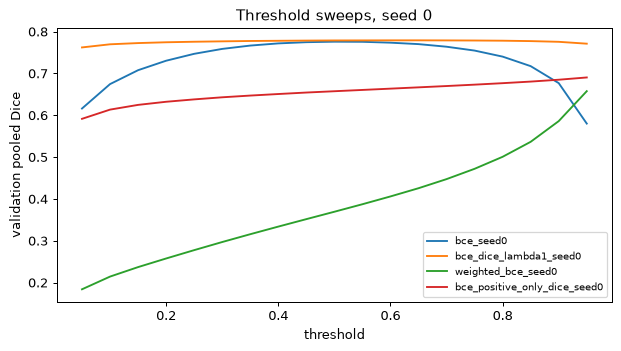

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for run in ["bce_seed0", "bce_dice_lambda1_seed0", "weighted_bce_seed0", "bce_positive_only_dice_seed0"]:
    sweep = pd.read_csv(RESULTS / "validation" / run / "threshold_sweep.csv")
    ax.plot(sweep.threshold, sweep.pooled_foreground_dice, label=run)
ax.set_xlabel("threshold")
ax.set_ylabel("validation pooled Dice")
ax.set_title("Threshold sweeps, seed 0")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Freeze and test-once checks

In [11]:
frozen_dir = RESULTS / "frozen_method"
manifest_path = frozen_dir / "frozen_method_manifest.json"
recorded_hash = (frozen_dir / "frozen_method_manifest.json.sha256").read_text().split()[0]
ledger = read_json(RESULTS / "test" / "test_evaluation_ledger.json")
manifest = read_json(manifest_path)

print("Manifest hash matches its .sha256 file:", sha256_of(manifest_path) == recorded_hash)
print("Ledger refers to the same manifest:   ", ledger["frozen_manifest_sha256"] == recorded_hash)
print("Frozen at:", manifest["frozen_at"], "| runs frozen:", len(manifest["runs"]))
print("Test attempts:", len(ledger["attempts"]))
for attempt in ledger["attempts"]:
    print("  ", attempt["started_at"], "->", attempt["finished_at"], "|", attempt["status"])
print("test_results.json hash matches ledger:",
      sha256_of(RESULTS / "test" / "test_results.json") == ledger["attempts"][-1]["results_sha256"])

code_matches = {path: sha256_of(PROJECT_ROOT / path) == digest for path, digest in manifest["code_sha256"].items()}
print("Evaluation code in this repository matches the frozen hashes:", all(code_matches.values()))

Manifest hash matches its .sha256 file: True
Ledger refers to the same manifest:    True
Frozen at: 2026-11-25T02:17:26+0000 | runs frozen: 14
Test attempts: 1
   2026-11-25T02:17:28+0000 -> 2026-11-25T02:17:46+0000 | completed
test_results.json hash matches ledger: True
Evaluation code in this repository matches the frozen hashes: True


## 6. Test summary (frozen methods, evaluated once)

In [12]:
test_by_condition = (pd.read_csv(TABLES / "test_summary_by_condition.csv")
                     .set_index("condition").loc[CONDITION_ORDER].reset_index())
test_by_condition[summary_columns]

,condition,n_seeds,pooled_foreground_dice_mean,pooled_foreground_dice_std,positive_slice_dice_mean,empty_slices_with_false_positives_mean,patient_dice_mean_mean
0,always_empty_reference,1,0.0000,NaN,0.0000,0.0000,0.0000
1,bce,3,0.8289,0.0101,0.7303,29.6667,0.7792
2,bce_dice_lambda1,3,0.7911,0.0268,0.6994,35.0000,0.7223
3,weighted_bce,3,0.7457,0.0102,0.6835,66.6667,0.6813
4,bce_positive_only_dice,3,0.7883,0.0477,0.7247,93.0000,0.7287
5,bce_dice_lambda0.5,1,0.7919,NaN,0.6764,29.0000,0.7056
6,bce_dice_lambda2,1,0.7957,NaN,0.6840,28.0000,0.7044


In [13]:
comparison = pd.DataFrame({
    "validation_dice_mean": val_by_condition.set_index("condition").pooled_foreground_dice_mean,
    "validation_dice_std": val_by_condition.set_index("condition").pooled_foreground_dice_std,
    "test_dice_mean": test_by_condition.set_index("condition").pooled_foreground_dice_mean,
    "test_dice_std": test_by_condition.set_index("condition").pooled_foreground_dice_std,
}).drop(index="always_empty_reference")
comparison["validation_rank"] = comparison.validation_dice_mean.rank(ascending=False).astype(int)
comparison["test_rank"] = comparison.test_dice_mean.rank(ascending=False).astype(int)
comparison

,validation_dice_mean,validation_dice_std,test_dice_mean,test_dice_std,validation_rank,test_rank
condition,,,,,,
bce,0.7586,0.0442,0.8289,0.0101,2,1
bce_dice_lambda1,0.7754,0.0080,0.7911,0.0268,1,4
weighted_bce,0.6848,0.0279,0.7457,0.0102,6,6
bce_positive_only_dice,0.7435,0.0464,0.7883,0.0477,4,5
bce_dice_lambda0.5,0.7382,NaN,0.7919,NaN,5,3
bce_dice_lambda2,0.7436,NaN,0.7957,NaN,3,2


In [14]:
test_by_run = pd.read_csv(TABLES / "test_summary_by_run.csv")
paired_seeds = (test_by_run.assign(seed=test_by_run.run_name.str.extract(r"seed(\d)$")[0])
                .query("condition in @MAIN_CONDITIONS")
                .pivot(index="seed", columns="condition", values="pooled_foreground_dice"))
paired_seeds["bce_dice_minus_bce"] = paired_seeds.bce_dice_lambda1 - paired_seeds.bce
print("Test pooled Dice by seed (main comparison):")
paired_seeds

Test pooled Dice by seed (main comparison):


condition,bce,bce_dice_lambda1,bce_dice_minus_bce
seed,,,
0,0.8176,0.8036,-0.0140
1,0.8319,0.7603,-0.0715
2,0.8373,0.8093,-0.0280


## 7. Paired per-patient comparison
Patient Dice is averaged over the three seeds of each condition. The Wilcoxon signed-rank test is an
exploratory, post-hoc check (it was not part of the pre-registered plan) and treats the 16–17 patients as
independent units.

In [15]:
paired_rows = []
for split in ["validation", "test"]:
    paired = pd.read_csv(TABLES / f"{split}_paired_patient_dice.csv")
    difference = paired.difference_proposed_minus_baseline
    nonzero = difference[difference != 0]
    paired_rows.append({
        "split": split,
        "patients": len(paired),
        "bce_dice_better": int((difference > 0).sum()),
        "bce_better": int((difference < 0).sum()),
        "ties": int((difference == 0).sum()),
        "mean_difference": difference.mean(),
        "median_difference": difference.median(),
        "wilcoxon_p": wilcoxon(nonzero).pvalue,
    })
pd.DataFrame(paired_rows)

,split,patients,bce_dice_better,bce_better,ties,mean_difference,median_difference,wilcoxon_p
0,validation,17,7,9,1,0.0013,-0.0005,0.8999
1,test,16,5,11,0,-0.0569,-0.0299,0.0182


In [16]:
pd.read_csv(TABLES / "test_paired_patient_dice.csv").sort_values("difference_proposed_minus_baseline").head(5)

,patient_id,bce,bce_dice_lambda1,difference_proposed_minus_baseline
0,TCGA_DU_5853,0.6743,0.4136,-0.2607
1,TCGA_CS_6290,0.7468,0.4889,-0.2579
2,TCGA_DU_8165,0.3942,0.2698,-0.1243
3,TCGA_DU_7299,0.4471,0.3341,-0.1130
4,TCGA_FG_7637,0.7797,0.7250,-0.0547


## 8. Lesion-size subgroups
Size groups are tertiles of lesion area on **training** slices (cut-offs from `figures.py`). The validation table
comes from `06_make_figures_and_tables.py`; the test breakdown below is computed here from the saved per-slice test
files with the same cut-offs (analysis only, no decisions are made from it).

In [17]:
val_size = pd.read_csv(TABLES / "validation_dice_by_lesion_size.csv")
cutoffs = [float(x) for x in val_size.cutoffs_pixels_from_training.iloc[0].split("/")]
print("Training tertile cut-offs (pixels):", cutoffs)
size_order = ["small", "medium", "large"]
(val_size.groupby(["condition", "lesion_size_group"]).mean_slice_dice.mean()
 .unstack()[size_order].loc[CONDITION_ORDER[1:]])

Training tertile cut-offs (pixels): [1038.0, 2350.67]


lesion_size_group,small,medium,large
condition,,,
bce,0.3526,0.7638,0.8176
bce_dice_lambda1,0.3435,0.7484,0.8151
weighted_bce,0.3463,0.7118,0.8155
bce_positive_only_dice,0.3708,0.7427,0.8093
bce_dice_lambda0.5,0.2785,0.6911,0.7698
bce_dice_lambda2,0.3006,0.6257,0.8278


In [18]:
size_rows = []
for run in record.run_name:
    slices = pd.read_csv(RESULTS / "test" / f"{run}_test_slices.csv")
    positive = slices[slices.ground_truth_empty == 0].copy()
    positive["lesion_size_group"] = pd.cut(positive.ground_truth_pixels, [-np.inf, *cutoffs, np.inf], labels=size_order)
    for group, part in positive.groupby("lesion_size_group", observed=True):
        size_rows.append({"run_name": run, "condition": test_by_run.set_index("run_name").condition[run],
                          "lesion_size_group": group, "n_slices": len(part), "mean_slice_dice": part.dice.mean()})
test_size = pd.DataFrame(size_rows)
print("Test positive slices per group:", test_size.query("run_name == 'bce_seed0'").set_index("lesion_size_group").n_slices.to_dict())
(test_size.groupby(["condition", "lesion_size_group"], observed=True).mean_slice_dice.mean()
 .unstack()[size_order].loc[CONDITION_ORDER[1:]])

Test positive slices per group: {'small': 62, 'medium': 59, 'large': 79}


lesion_size_group,small,medium,large
condition,,,
bce,0.4927,0.7782,0.8810
bce_dice_lambda1,0.4571,0.7333,0.8644
weighted_bce,0.4631,0.7128,0.8346
bce_positive_only_dice,0.5084,0.7641,0.8651
bce_dice_lambda0.5,0.4743,0.6874,0.8267
bce_dice_lambda2,0.3853,0.7639,0.8586


## 9. Figures written by `06_make_figures_and_tables.py`

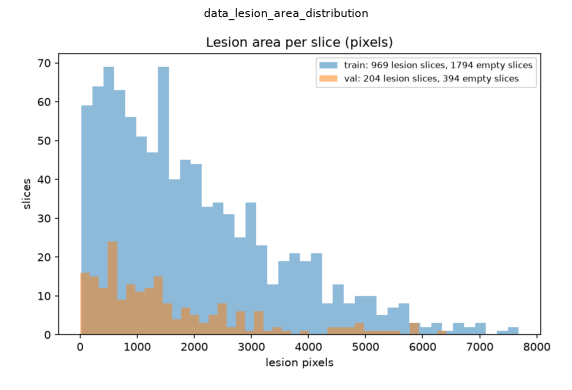

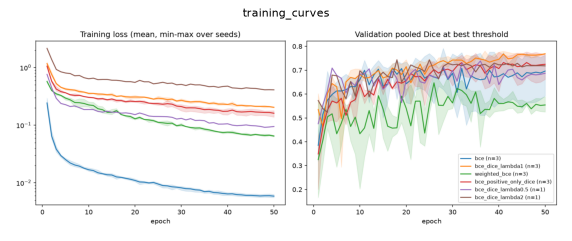

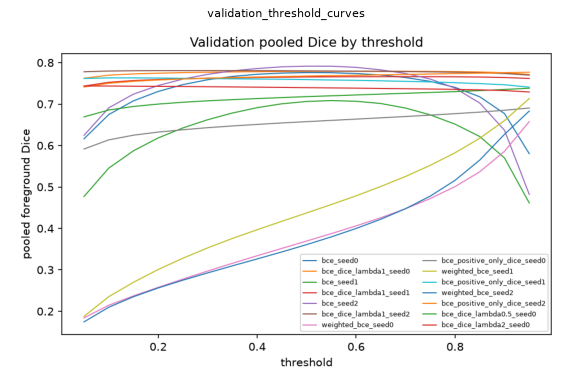

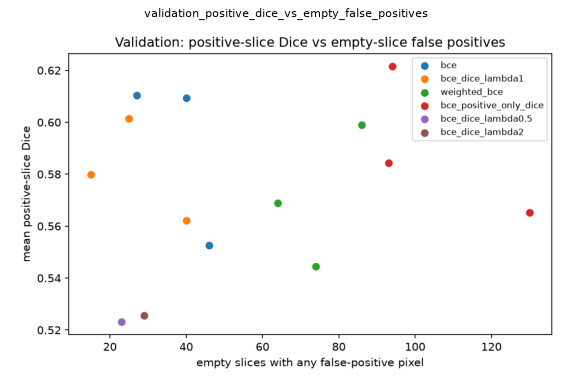

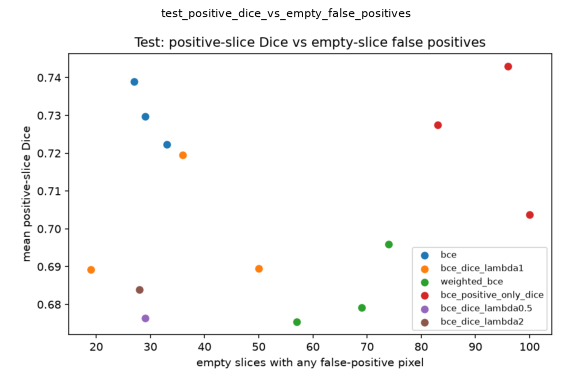

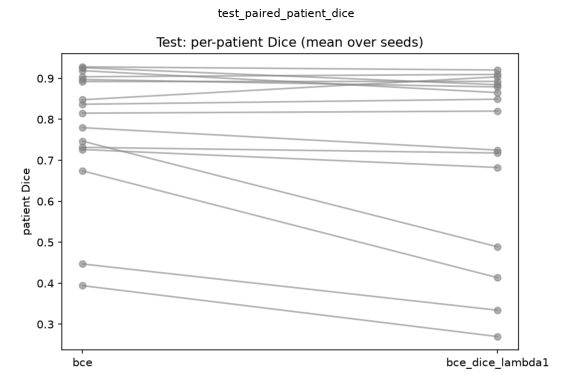

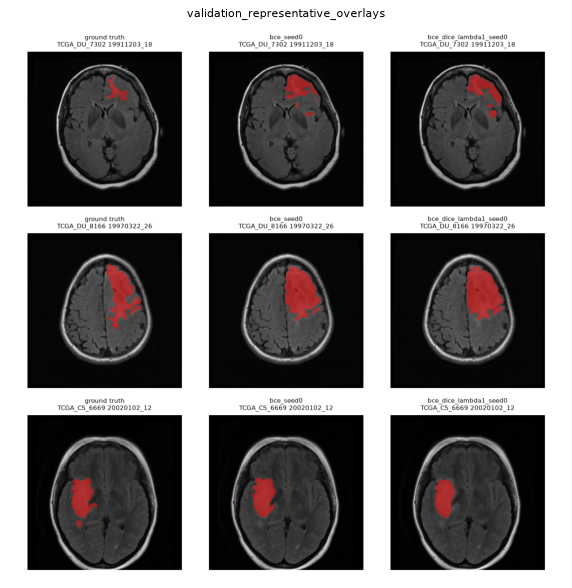

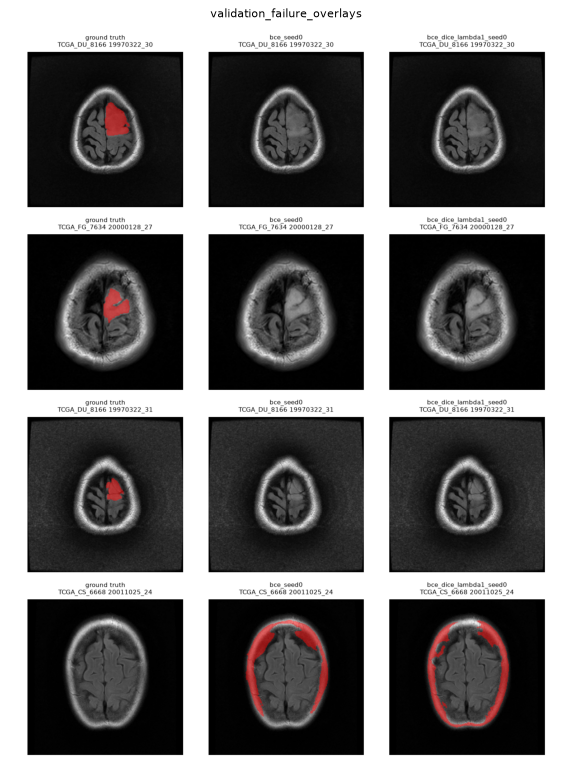

In [19]:
for name in [
    "data_lesion_area_distribution", "training_curves", "validation_threshold_curves",
    "validation_positive_dice_vs_empty_false_positives", "test_positive_dice_vs_empty_false_positives",
    "test_paired_patient_dice", "validation_representative_overlays", "validation_failure_overlays",
]:
    image = plt.imread(FIGURES / f"{name}.png")
    height, width = image.shape[:2]
    fig, ax = plt.subplots(figsize=(8, 8 * height / width))
    ax.imshow(image)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
    plt.show()

## Summary
* Validation slightly favoured BCE + Dice (higher mean pooled Dice, smaller seed spread).
* On the one-time test evaluation BCE alone scored higher, and BCE + Dice was worse for most test patients.
* Weighted BCE did not reproduce any gain; positive-only Dice produced many more false positives on empty slices.
* Several diagnostic and sensitivity runs chose a threshold at the edge of the grid.
* Small lesions remain the main failure mode for every loss.

The numbers behind each statement are printed in the cells above.